<a href="https://colab.research.google.com/github/Harsh3j53/AMLBT/blob/main/Promo_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Environment Setup & Google Drive Mount

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Define Paths and Constants

In [ ]:
BASE = '/content/drive/MyDrive/promo_forecasting'
DATA = f'{BASE}/data'
SEED = 42

## 3. Load Datasets

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

train    = pd.read_csv(f'{DATA}/train.csv', parse_dates=['date'])
stores   = pd.read_csv(f'{DATA}/stores.csv')
holidays = pd.read_csv(f'{DATA}/holidays_events.csv', parse_dates=['date'])

print(train.shape, stores.shape, holidays.shape)

(3000888, 6) (54, 5) (350, 6)


## 4. Optimize Column Data Types

In [ ]:
train['store_nbr']    = train['store_nbr'].astype('int16')
train['family']       = train['family'].astype('category')
train['sales']        = train['sales'].astype('float32')
train['onpromotion']  = train['onpromotion'].astype('int16')
train = train.drop(columns=['id'])

## 5. Exploratory Data Quality Check

In [ ]:
print(train.isna().sum())
print(train.date.min(), train.date.max(), train.date.nunique())
print(train.duplicated(['date','store_nbr','family']).sum(), 'duplicate keys')
print('First promo date:', train[train.onpromotion > 0].date.min())

date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64
2013-01-01 00:00:00 2017-08-15 00:00:00 1684
0 duplicate keys
First promo date: 2014-04-01 00:00:00


## 6. Export Cleaned Dataset to Parquet

In [ ]:
train.to_parquet(f'{BASE}/train_clean.parquet')

In [ ]:
all_dates = pd.date_range(train.date.min(), train.date.max())
missing = all_dates.difference(train.date.unique())
print(len(missing), 'missing dates')
print(missing)

4 missing dates
DatetimeIndex(['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25'], dtype='datetime64[ns]', freq=None)


In [ ]:
g = train.groupby(['store_nbr','family'], observed=True)['sales']
series_stats = g.agg(total='sum', zero_share=lambda s: (s==0).mean()).reset_index()

print((series_stats.total == 0).sum(), 'series that are zero for all time')
print(series_stats.sort_values('zero_share', ascending=False).head(15))

# zero share by family
zero_by_family = series_stats.groupby('family', observed=True)['zero_share'].mean().sort_values(ascending=False)
print(zero_by_family)

53 series that are zero for all time
      store_nbr      family  total  zero_share
1753         54       BOOKS    0.0         1.0
1618         50   BABY CARE    0.0         1.0
1585         49   BABY CARE    0.0         1.0
1519         47   BABY CARE    0.0         1.0
1486         46   BABY CARE    0.0         1.0
1552         48   BABY CARE    0.0         1.0
1687         52       BOOKS    0.0         1.0
1453         45   BABY CARE    0.0         1.0
1420         44   BABY CARE    0.0         1.0
1390         43       BOOKS    0.0         1.0
1405         43  LADIESWEAR    0.0         1.0
1159         36       BOOKS    0.0         1.0
1258         39       BOOKS    0.0         1.0
1291         40       BOOKS    0.0         1.0
1306         40  LADIESWEAR    0.0         1.0
family
BOOKS                         0.969550
BABY CARE                     0.941310
SCHOOL AND OFFICE SUPPLIES    0.740829
HOME APPLIANCES               0.735176
LADIESWEAR                    0.598465
MAGAZINES

In [ ]:
first_sale = (train[train.sales > 0].groupby('store_nbr')['date'].min()
              .rename('first_sale_date').reset_index())
print(first_sale.sort_values('first_sale_date').tail(12))

    store_nbr first_sale_date
17         18      2013-01-02
18         19      2013-01-02
13         14      2013-01-02
53         54      2013-01-02
35         36      2013-05-09
52         53      2014-05-29
19         20      2015-02-13
28         29      2015-03-20
20         21      2015-07-24
41         42      2015-08-21
21         22      2015-10-09
51         52      2017-04-20


In [ ]:
promo_era = train[train.date >= '2014-04-01']

# share of days with a promotion, by family
promo_family = (promo_era.assign(promo=promo_era.onpromotion > 0)
                .groupby('family', observed=True)['promo'].mean()
                .sort_values(ascending=False))
print(promo_family)

# by store
promo_store = (promo_era.assign(promo=promo_era.onpromotion > 0)
               .groupby('store_nbr')['promo'].mean().sort_values())
print(promo_store.head(10)); print(promo_store.tail(10))

family
GROCERY I                     0.856459
BEVERAGES                     0.778455
CLEANING                      0.751280
DAIRY                         0.692337
DELI                          0.594384
BREAD/BAKERY                  0.585607
PERSONAL CARE                 0.575595
FROZEN FOODS                  0.539295
HOME CARE                     0.489883
PRODUCE                       0.463475
EGGS                          0.413746
MEATS                         0.323216
POULTRY                       0.296658
HOME AND KITCHEN II           0.285818
LIQUOR,WINE,BEER              0.269753
PREPARED FOODS                0.266155
SEAFOOD                       0.249413
HOME AND KITCHEN I            0.219843
BEAUTY                        0.167374
LAWN AND GARDEN               0.063716
GROCERY II                    0.062406
SCHOOL AND OFFICE SUPPLIES    0.061036
CELEBRATION                   0.048344
AUTOMOTIVE                    0.045980
PET SUPPLIES                  0.045965
LINGERIE          

In [ ]:
cmp = (promo_era.assign(promo=promo_era.onpromotion > 0)
       .groupby(['family','promo'], observed=True)['sales'].mean()
       .unstack())
cmp['ratio'] = cmp[True] / cmp[False]
print(cmp.sort_values('ratio', ascending=False))

promo                             False         True      ratio
family                                                         
SCHOOL AND OFFICE SUPPLIES     1.358096    44.529106  32.787899
BABY CARE                      0.149035     1.660377  11.140862
PET SUPPLIES                   4.636451    15.835244   3.415380
HOME APPLIANCES                0.436093     1.396552   3.202418
HOME AND KITCHEN II           14.839405    41.158134   2.773570
BEVERAGES                   1252.226929  3215.498291   2.567824
LAWN AND GARDEN                6.561909    16.786861   2.558228
FROZEN FOODS                  92.610847   228.997528   2.472686
BEAUTY                         3.353706     8.291265   2.472270
GROCERY I                   1995.297485  4411.003418   2.210700
PLAYERS AND ELECTRONICS        7.858139    17.363958   2.209678
PRODUCE                     1149.713013  2438.220215   2.120721
AUTOMOTIVE                     6.247656    13.241978   2.119511
LADIESWEAR                     9.136371 

### 6b. Modeling Scope & Stratified Sampling
#### Defining Target Families and Representative Stores
Before reconstructing full timelines and engineering complex features, we narrow down our modeling focus. Here we define our 8 target product families, filter out stores that did not have sales before our target start date, and perform a stratified random sample to select 15 representative stores across all store types.

In [ ]:
print(holidays.type.value_counts()); print(holidays.locale.value_counts())
print(holidays.transferred.value_counts())
print(stores.type.value_counts())

type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64
transferred
False    338
True      12
Name: count, dtype: int64
type
D    18
C    15
A     9
B     8
E     4
Name: count, dtype: int64


In [ ]:
FAMILIES = ['GROCERY I','BEVERAGES','CLEANING','DAIRY',
            'BREAD/BAKERY','PERSONAL CARE','PRODUCE','MEATS']
PROMO_START = pd.Timestamp('2014-04-01')

# stores that were selling before promo data begins
first_sale = train[train.sales > 0].groupby('store_nbr')['date'].min()
eligible = first_sale[first_sale < PROMO_START].index
st = stores[stores.store_nbr.isin(eligible)]

# stratified sample: up to 3 stores per type
STORES = (st.groupby('type', group_keys=False)
            .apply(lambda g: g.sample(min(len(g), 3), random_state=SEED))
            .store_nbr.tolist())
print(len(STORES), sorted(STORES))
print(stores[stores.store_nbr.isin(STORES)].type.value_counts())

15 [1, 2, 6, 9, 10, 11, 28, 32, 35, 36, 39, 43, 44, 45, 49]
type
D    3
B    3
C    3
E    3
A    3
Name: count, dtype: int64


/tmp/ipykernel_538/3353904651.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 3), random_state=SEED))


In [ ]:
# filter and check
sub = train[train.family.isin(FAMILIES) & train.store_nbr.isin(STORES)].copy()
sub['family'] = sub['family'].astype(str)
print(sub.shape)

# zero check after promo start (should be low now)
chk = sub[sub.date >= PROMO_START]
print('zero share:', (chk.sales == 0).mean().round(4))
print(chk.groupby('family')['sales'].mean().round(1))

sub.to_parquet(f'{BASE}/scope_8fam.parquet')

(202080, 5)
zero share: 0.02
family
BEVERAGES        3532.100098
BREAD/BAKERY      613.299988
CLEANING         1334.900024
DAIRY             964.500000
GROCERY I        4977.000000
MEATS             440.299988
PERSONAL CARE     329.899994
PRODUCE          2208.100098
Name: sales, dtype: float32


### 7. Time Series Reconstruction & Alignment
#### Handling Gaps (e.g., Christmas Day Gaps)
This section expands the sampled dataset into a complete, continuous daily time series index for every combination of store and product family. This ensures we don't have gaps when calculating historical lag features.

In [ ]:
sub = pd.read_parquet(f'{BASE}/scope_8fam.parquet')

full_dates = pd.date_range(sub.date.min(), sub.date.max())
idx = pd.MultiIndex.from_product([STORES, FAMILIES, full_dates],
                                 names=['store_nbr','family','date'])
df = (sub.set_index(['store_nbr','family','date'])
         .reindex(idx).reset_index()
         .sort_values(['store_nbr','family','date']).reset_index(drop=True))
print(df.shape, df.sales.isna().sum(), 'missing rows (should be the Dec 25 gaps)')

(202560, 5) 480 missing rows (should be the Dec 25 gaps)


### 8. Temporal Feature Engineering
#### Calendar, Weekly, & Payday Signals
Here we extract basic datetime properties—such as day of week, month, and day of month—and construct specific boolean flags representing weekends and bi-weekly/monthly government payday effects.

In [ ]:
df['dow']        = df.date.dt.dayofweek
df['month']      = df.date.dt.month
df['dom']        = df.date.dt.day
df['is_weekend'] = (df.dow >= 5).astype(int)
df['is_payday']  = ((df.dom == 15) | df.date.dt.is_month_end).astype(int)

### 9. Historical Sales Lag & Rolling Statistics
#### Autoregressive Modeling Features
This step computes critical lag features (sales from 7, 14, and 28 days ago) and rolling averages/standard deviations. These statistics provide the predictive models with context regarding recent sales trends.

In [ ]:
g = df.groupby(['store_nbr','family'])['sales']

for L in [7, 14, 28]:
    df[f'lag_{L}'] = g.shift(L)

df['roll7_mean']  = g.transform(lambda s: s.shift(7).rolling(7).mean())
df['roll28_mean'] = g.transform(lambda s: s.shift(7).rolling(28).mean())
df['roll7_std']   = g.transform(lambda s: s.shift(7).rolling(7).std())

### 10. Promotion Lag & Trend Features
#### Anticipating Promotion Effects
Because promotions significantly boost product sales, we construct features tracking current and historical promotional activity (lagged promotion status and rolling promotional intensity).

In [ ]:
gp = df.groupby(['store_nbr','family'])['onpromotion']

df['promo_flag']  = (df.onpromotion > 0).astype(int)
df['promo_lag7']  = gp.shift(7)
df['promo_roll7'] = gp.transform(lambda s: s.rolling(7).mean())
df['promo_roll28']= gp.transform(lambda s: s.rolling(28).mean())

### 11. Store Metadata & Holiday Calendar Integration
#### Regional and National Calendar Adjustments
This block merges static store characteristics (city, state, store type, cluster) and overlays local, regional, and national holiday markers onto our timeline to account for holiday shopping surges.

In [ ]:
df = df.merge(stores[['store_nbr','city','state','type','cluster']],
              on='store_nbr', how='left')

h = holidays[(~holidays.transferred) & (~holidays.type.isin(['Work Day','Event']))]

nat = h[h.locale=='National'].date.drop_duplicates()
df['hol_national'] = df.date.isin(nat).astype(int)

reg = (h[h.locale=='Regional'][['date','locale_name']]
       .rename(columns={'locale_name':'state'}).drop_duplicates().assign(hol_regional=1))
loc = (h[h.locale=='Local'][['date','locale_name']]
       .rename(columns={'locale_name':'city'}).drop_duplicates().assign(hol_local=1))

df = df.merge(reg, on=['date','state'], how='left').merge(loc, on=['date','city'], how='left')
df[['hol_regional','hol_local']] = df[['hol_regional','hol_local']].fillna(0).astype(int)
df['is_holiday'] = df[['hol_national','hol_regional','hol_local']].max(axis=1)
print(df[['hol_national','hol_regional','hol_local','is_holiday']].sum())

hol_national     9840
hol_regional        0
hol_local         816
is_holiday      10648
dtype: int64


### 12. Dataset Pruning & Feature Saving
#### Filtering and Exporting to Parquet
Finally, we filter out early records that do not have enough historical history to populate our 28-day lags. Once missing rows are cleaned, we save the completed model-ready dataset as a high-performance Parquet file.

In [ ]:
FEATURE_START = PROMO_START + pd.Timedelta(days=28)   # 2014-04-29

df = df[(df.date >= FEATURE_START) & df.sales.notna()].copy()
df = df.dropna(subset=['lag_7','lag_14','lag_28','roll28_mean','promo_lag7','promo_roll28'])

print(df.shape)
print(df.isna().sum().loc[lambda x: x > 0])
df.to_parquet(f'{BASE}/features.parquet')

(132000, 28)
Series([], dtype: int64)


### 13. Data Splitting
#### Defining Validation and Holdout Sets
To evaluate our predictive performance without data leakage, we divide our dataset chronologically. The last 28 days are reserved as our final holdout test window, and the 28 days prior serve as our validation window.

In [ ]:
df = pd.read_parquet(f'{BASE}/features.parquet')

HOLDOUT_DAYS, VAL_DAYS = 28, 28
last       = df.date.max()
HOLD_START = last - pd.Timedelta(days=HOLDOUT_DAYS - 1)
VAL_START  = HOLD_START - pd.Timedelta(days=VAL_DAYS)

train_df = df[df.date <  VAL_START]
val_df   = df[(df.date >= VAL_START) & (df.date < HOLD_START)]
hold_df  = df[df.date >= HOLD_START]

for name, d in [('train', train_df), ('val', val_df), ('holdout', hold_df)]:
    print(f"{name:8s} {d.date.min().date()} to {d.date.max().date()} | "
          f"rows {len(d):>7,} | promo days {(d.onpromotion>0).mean():.1%} | "
          f"avg sales {d.sales.mean():,.0f}")

train    2014-04-29 to 2017-06-20 | rows 125,280 | promo days 66.8% | avg sales 1,803
val      2017-06-21 to 2017-07-18 | rows   3,360 | promo days 91.0% | avg sales 2,077
holdout  2017-07-19 to 2017-08-15 | rows   3,360 | promo days 86.6% | avg sales 2,005


### 14. Feature Subsets Definition
#### Isolating Promotional Effects
We define two distinct feature spaces to isolate the impact of promotions: Set A represents our baseline calendar, holiday, lag, and store attributes, while Set B incorporates all explicit promotional indicators.

In [ ]:
CAL    = ['dow','month','dom','is_weekend','is_payday']
HOL    = ['is_holiday','hol_national','hol_regional','hol_local']
SALES  = ['lag_7','lag_14','lag_28','roll7_mean','roll28_mean','roll7_std']
STORE  = ['store_nbr','family','type','cluster']
PROMO  = ['onpromotion','promo_flag','promo_lag7','promo_roll7','promo_roll28']

FEATS_A = CAL + HOL + SALES + STORE            # without promotion info
FEATS_B = FEATS_A + PROMO                      # promotion-aware
TARGET  = 'sales'

print(len(FEATS_A), 'features in A;', len(FEATS_B), 'in B')

19 features in A; 24 in B


### 15. Promotional Intensity Analysis
#### Evaluating Group Behaviors on Validation and Holdout Sets
Here, we examine the distribution and frequency of promotional flags across both test periods to ensure our evaluation splits contain representative promotional distributions.

In [ ]:
val_promo  = (val_df.onpromotion  > 0).values
hold_promo = (hold_df.onpromotion > 0).values
print(val_promo.mean().round(3), hold_promo.mean().round(3))

0.91 0.866


In [ ]:
for name, d in [('val', val_df), ('holdout', hold_df)]:
    print(name)
    print(d.assign(promo=d.onpromotion > 0)
           .groupby('family').promo.agg(share='mean', non_promo_rows=lambda s: (~s).sum()).round(2))

print(hold_df.onpromotion.describe().round(1))

val
               share  non_promo_rows
family                              
BEVERAGES       1.00               0
BREAD/BAKERY    0.91              36
CLEANING        1.00               0
DAIRY           1.00               0
GROCERY I       1.00               0
MEATS           0.38             262
PERSONAL CARE   1.00               0
PRODUCE         0.99               5
holdout
               share  non_promo_rows
family                              
BEVERAGES       1.00               1
BREAD/BAKERY    0.78              92
CLEANING        1.00               1
DAIRY           1.00               2
GROCERY I       1.00               1
MEATS           0.16             351
PERSONAL CARE   1.00               1
PRODUCE         1.00               1
count    3360.0
mean       22.1
std        30.2
min         0.0
25%         6.0
50%        13.0
75%        25.0
max       425.0
Name: onpromotion, dtype: float64


### 16. Threshold-Based Stratification
#### Splitting Promotions into Low vs. High Intensity
Using historical medians per product family, we categorize promotional events into low and high groups. This categorization allows us to assess model robustness under varying promotion levels.

In [ ]:
thr = train_df[train_df.onpromotion > 0].groupby('family').onpromotion.median()

def add_group(d):
    t = d.family.map(thr)
    d = d.copy()
    d['promo_group'] = np.select([d.onpromotion == 0, d.onpromotion < t],
                                 ['none', 'low'], default='high')
    return d

train_df, val_df, hold_df = add_group(train_df), add_group(val_df), add_group(hold_df)
print(val_df.promo_group.value_counts()); print(hold_df.promo_group.value_counts())

promo_group
high    2782
none     303
low      275
Name: count, dtype: int64
promo_group
high    2725
none     450
low      185
Name: count, dtype: int64


### 17. Baseline Model Evaluation
#### Measuring Performance with Naive Baselines
Before building complex ML pipelines, we evaluate simple baseline predictors (the 7-day seasonal naive lag and a rolling 7-day moving average) to set our minimum performance standards.

In [ ]:
def metrics(y, p):
    return pd.Series({'MAE': np.mean(np.abs(y - p)),
                      'RMSE': np.sqrt(np.mean((y - p) ** 2))})

def report(d, pred):
    y, rows = d.sales.values, {'all': None}
    out = {'all': metrics(y, pred)}
    counts = {'all': len(y)}
    for g in ['none', 'low', 'high']:
        m = (d.promo_group == g).values
        if m.sum() > 0:
            out[g], counts[g] = metrics(y[m], pred[m]), int(m.sum())
    r = pd.DataFrame(out).T.round(1)
    r['n'] = pd.Series(counts)
    return r

print('Seasonal naive (lag_7), validation')
print(report(val_df, val_df.lag_7.values))
print('7-day moving average, validation')
print(report(val_df, val_df.roll7_mean.values))

Seasonal naive (lag_7), validation
             MAE        RMSE     n
all   343.899994  744.400024  3360
none   74.400002  113.000000   303
low   161.600006  426.200012   275
high  391.200012  806.200012  2782
7-day moving average, validation
        MAE    RMSE     n
all   512.1  1032.9  3360
none  121.4   187.0   303
low   212.9   493.5   275
high  584.2  1122.8  2782


### 18. Model Comparison Framework
#### Tracking Key Metrics Across Experiments
This helper script establishes a tracking table storing metrics like Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE) across our modeling pipeline.

In [ ]:
def wape(y, p):
    return np.abs(y - p).sum() / y.sum() * 100

def summarize(d, pred, model, feats):
    y = d.sales.values
    row = {'model': model, 'features': feats,
           'MAE': np.mean(np.abs(y - pred)),
           'RMSE': np.sqrt(np.mean((y - pred) ** 2)),
           'WAPE%': wape(y, pred)}
    for g in ['none', 'low', 'high']:
        m = (d.promo_group == g).values
        row[f'WAPE_{g}%'] = wape(y[m], pred[m])
    return row

results = [summarize(val_df, val_df.lag_7.values, 'Seasonal naive', '-')]
pd.DataFrame(results).round(1)

,model,features,MAE,RMSE,WAPE%,WAPE_none%,WAPE_low%,WAPE_high%
0,Seasonal naive,-,343.899994,744.400024,16.6,15.7,17.4,16.5


### 19. Initial Model Development
#### Evaluating Linear Regression and XGBoost on Validation Data
In this section, we train our first machine learning pipelines (Linear Regression and XGBoost) on our feature sets and evaluate their performance on the validation timeline.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

CATS = ['store_nbr', 'family', 'type', 'cluster']
levels = {c: sorted(df[c].unique()) for c in CATS}     # labels only, no leakage

def prep(d, feats):
    X = d[feats].copy()
    for c in CATS:
        X[c] = pd.Categorical(X[c], categories=levels[c])
    return X

def make_lr():
    ct = ColumnTransformer([('oh', OneHotEncoder(handle_unknown='ignore'), CATS)],
                           remainder='passthrough')
    return make_pipeline(ct, LinearRegression())

def make_xgb():
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8,
                        enable_categorical=True, tree_method='hist',
                        random_state=SEED, n_jobs=-1)

for model_name, maker in [('Linear Regression', make_lr), ('XGBoost', make_xgb)]:
    for set_name, feats in [('A (no promo)', FEATS_A), ('B (promo-aware)', FEATS_B)]:
        m = maker()
        m.fit(prep(train_df, feats), np.log1p(train_df.sales))
        pred = np.clip(np.expm1(m.predict(prep(val_df, feats))), 0, None)
        results.append(summarize(val_df, pred, model_name, set_name))

res = pd.DataFrame(results).round(1)
print(res.to_string(index=False))

            model        features    MAE   RMSE  WAPE%  WAPE_none%  WAPE_low%  WAPE_high%
   Seasonal naive               -  343.9  744.4   16.6        15.7       17.4        16.5
Linear Regression    A (no promo) 1585.8 6076.2   76.4        32.0       52.8        78.2
Linear Regression B (promo-aware) 1914.8 7226.9   92.2        35.5       51.2        95.0
          XGBoost    A (no promo)  194.4  447.7    9.4        10.2        7.7         9.4
          XGBoost B (promo-aware)  188.3  420.7    9.1        12.2        7.6         9.1


### 20. Family-Level Validation Analysis
#### Investigating Model Performance by Product Category
To understand where our models excel and struggle, we dissect the validation WAPE metrics individually across our 8 major product families.

In [ ]:
preds = {}
for set_name, feats in [('A', FEATS_A), ('B', FEATS_B)]:
    m = make_xgb().fit(prep(train_df, feats), np.log1p(train_df.sales))
    preds[set_name] = np.clip(np.expm1(m.predict(prep(val_df, feats))), 0, None)

fam = []
for f in FAMILIES:
    mk = (val_df.family == f).values
    y = val_df.sales.values[mk]
    fam.append({'family': f, 'baseline': wape(y, val_df.lag_7.values[mk]),
                'XGB_A': wape(y, preds['A'][mk]), 'XGB_B': wape(y, preds['B'][mk])})
print(pd.DataFrame(fam).round(1).to_string(index=False))

       family  baseline  XGB_A  XGB_B
    GROCERY I 18.100000    8.0    7.6
    BEVERAGES 15.800000    9.9   10.0
     CLEANING 27.400000   14.5   14.3
        DAIRY 12.400000    7.4    7.9
 BREAD/BAKERY 12.600000    9.5    9.4
PERSONAL CARE 28.299999   12.4   12.3
      PRODUCE 10.200000    8.6    7.3
        MEATS 17.600000   10.5   12.5


### 21. Refining Linear Regression
#### Log Transformations for Skewed Target Distributions
Standard Linear Regression struggles with skewed target distributions. Here, we retrain Linear Regression applying a log1p transformation to our feature spaces to stabilize variances.

In [ ]:
from sklearn.preprocessing import FunctionTransformer

LOGCOLS = ['lag_7','lag_14','lag_28','roll7_mean','roll28_mean','roll7_std']
PROMOLOG = ['onpromotion','promo_lag7','promo_roll7','promo_roll28']
ONEHOT = ['store_nbr','family','type','cluster','dow','month']

def make_lr2(feats):
    logs  = [c for c in LOGCOLS + PROMOLOG if c in feats]
    other = [c for c in feats if c not in logs + ONEHOT]
    ct = ColumnTransformer([
        ('oh',  OneHotEncoder(handle_unknown='ignore'), ONEHOT),
        ('log', FunctionTransformer(np.log1p, validate=False), logs),
        ('rest', 'passthrough', other)])
    return make_pipeline(ct, LinearRegression())

lr_rows = []
for set_name, feats in [('A (no promo)', FEATS_A), ('B (promo-aware)', FEATS_B)]:
    m = make_lr2(feats).fit(train_df[feats], np.log1p(train_df.sales))
    pred = np.clip(np.expm1(m.predict(val_df[feats])), 0, None)
    lr_rows.append(summarize(val_df, pred, 'Linear Regression (fixed)', set_name))
print(pd.DataFrame(lr_rows).round(1).to_string(index=False))

                    model        features   MAE  RMSE  WAPE%  WAPE_none%  WAPE_low%  WAPE_high%
Linear Regression (fixed)    A (no promo) 309.0 625.1   14.9        17.3       13.9        14.9
Linear Regression (fixed) B (promo-aware) 368.6 713.8   17.7        15.6       13.8        18.0


### 22. Cross-Validation over Time Windows
#### Backtesting Stability Across Historical Shifts
We validate our XGBoost models across 6 rolling historical windows to verify that model performance remains robust and stable over different time horizons.

In [ ]:
origins = [VAL_START - pd.Timedelta(days=56 * k) for k in range(6)]
rows = []
for start in origins:
    end = start + pd.Timedelta(days=28)
    tr = df[df.date < start]
    te = df[(df.date >= start) & (df.date < end)]
    y = te.sales.values
    out = {'window_start': start.date(), 'baseline': wape(y, te.lag_7.values)}
    for set_name, feats in [('A', FEATS_A), ('B', FEATS_B)]:
        m = make_xgb().fit(prep(tr, feats), np.log1p(tr.sales))
        p = np.clip(np.expm1(m.predict(prep(te, feats))), 0, None)
        out[f'XGB_{set_name}'] = wape(y, p)
    out['promo_share'] = (te.onpromotion > 0).mean() * 100
    rows.append(out)

ro = pd.DataFrame(rows)
ro['B_minus_A'] = ro.XGB_B - ro.XGB_A
print(ro.round(2).to_string(index=False))
print('B better in', (ro.B_minus_A < 0).sum(), 'of', len(ro), 'windows; mean diff', ro.B_minus_A.mean().round(2))

window_start  baseline  XGB_A  XGB_B  promo_share  B_minus_A
  2017-06-21 16.559999   9.36   9.07        90.98      -0.29
  2017-04-26 21.010000  12.27  12.12        91.04      -0.15
  2017-03-01 17.750000  12.24  11.98        87.29      -0.27
  2017-01-04 14.190000  11.89  12.19        87.50       0.30
  2016-11-09 18.250000  12.90  11.90        88.36      -1.00
  2016-09-14 16.870001  10.89  11.67        87.80       0.77
B better in 4 of 6 windows; mean diff -0.1


### 23. Analyzing Extreme Category Shifts
#### Investigating Meat Sales on Promotions
To diagnose specific edge cases, we analyze historical behaviors within the MEATS category to investigate how demand shifts during active promotions.

In [ ]:
mk = (val_df.family == 'MEATS').values
print(val_df[mk].groupby(val_df[mk].onpromotion > 0).sales.agg(['mean', 'count']).round(0))
print(train_df[train_df.family == 'MEATS'].groupby(train_df.onpromotion > 0).sales.agg(['mean', 'count']).round(0))

              mean  count
onpromotion              
False        413.0    262
True         530.0    158
              mean  count
onpromotion              
False        385.0  10333
True         553.0   5327


### 24. Final Holdout Evaluation
#### Re-training on Full History & Evaluating on Test Split
We combine our training and validation datasets into a single unified training set, re-fit our final models, and report final unbiased metrics on our unseen holdout test split.

In [ ]:
full_train = pd.concat([train_df, val_df])

def final_pred(model_name, feats):
    if model_name == 'Linear Regression':
        m = make_lr2(feats).fit(full_train[feats], np.log1p(full_train.sales))
        return np.clip(np.expm1(m.predict(hold_df[feats])), 0, None)
    m = make_xgb().fit(prep(full_train, feats), np.log1p(full_train.sales))
    return np.clip(np.expm1(m.predict(prep(hold_df, feats))), 0, None)

final = [summarize(hold_df, hold_df.lag_7.values, 'Same as last week', '-')]
for name in ['Linear Regression', 'XGBoost']:
    for set_name, feats in [('A (no promo)', FEATS_A), ('B (promo-aware)', FEATS_B)]:
        final.append(summarize(hold_df, final_pred(name, feats), name, set_name))

print(pd.DataFrame(final).round(1).to_string(index=False))

            model        features   MAE  RMSE  WAPE%  WAPE_none%  WAPE_low%  WAPE_high%
Same as last week               - 338.0 689.6   16.9        16.1       15.9        16.9
Linear Regression    A (no promo) 297.1 596.9   14.8        14.4       13.8        14.9
Linear Regression B (promo-aware) 311.1 593.4   15.5        23.8       14.5        15.2
          XGBoost    A (no promo) 294.5 673.2   14.7        12.1       12.6        14.8
          XGBoost B (promo-aware) 244.0 505.5   12.2        15.1       12.3        12.1


### 25. Feature Importance Analysis
#### Visualizing XGBoost Model Drivers
We extract and plot the top feature importances from our best-performing XGBoost model to understand what variables drive our sales forecasts.

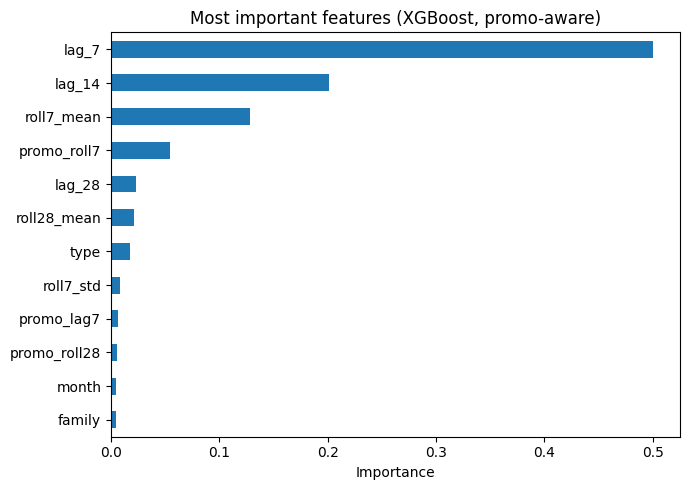

In [ ]:
import matplotlib.pyplot as plt

m = make_xgb().fit(prep(full_train, FEATS_B), np.log1p(full_train.sales))
imp = pd.Series(m.feature_importances_, index=FEATS_B).sort_values()

imp.tail(12).plot(kind='barh', figsize=(7, 5))
plt.title('Most important features (XGBoost, promo-aware)')
plt.xlabel('Importance')
plt.tight_layout(); plt.show()

### 26. Supply Chain Inventory Simulator
#### Framing Forecasts into Business Decisions
We build an inventory simulation environment that models order arrival lead times and safety stocks. This translates mathematical forecasts into actual business metrics such as shortage units and average stock levels.

In [ ]:
def simulate(actual, fc, lead=3, ss=0.1):
    n = len(actual)
    on_hand = fc[:lead + 1].mean() * (lead + 1) * (1 + ss)   # starting stock
    arrivals = np.zeros(n + lead + 2)
    short, stock_sum = 0.0, 0.0
    for t in range(n):
        on_hand += arrivals[t]                       # orders arriving today
        sold = min(on_hand, actual[t])
        short += actual[t] - sold                    # missed sales
        on_hand -= sold
        stock_sum += on_hand                         # leftover stock
        pipeline = arrivals[t + 1:].sum()            # orders on the way
        nxt = fc[t + 1:t + lead + 2]
        need = (nxt.mean() if len(nxt) else fc[t]) * (lead + 1) * (1 + ss)
        order = max(0.0, need - on_hand - pipeline)
        arrivals[t + lead] += order if lead >= 1 else 0
    return short, stock_sum / n

### 27. Business Impact & Policy Evaluation
#### Assessing Lead Times, Safety Stocks, and Forecast Alignment
Finally, we run our full simulator across different supply chain settings (lead times and safety stock levels) to assess the bottom-line savings and service levels achieved by utilizing a promotion-aware forecasting model.

In [ ]:
H = hold_df[['store_nbr', 'family', 'date', 'sales']].copy()
H['Same as last week'] = hold_df.lag_7.values
H['XGBoost (no promo)'] = final_pred('XGBoost', FEATS_A)
H['XGBoost (promo-aware)'] = final_pred('XGBoost', FEATS_B)
H = H.sort_values(['store_nbr', 'family', 'date'])

methods = ['Same as last week', 'XGBoost (no promo)', 'XGBoost (promo-aware)']
rows = []
for lead in [1, 3, 7]:
    for ss in [0.0, 0.1, 0.2]:
        for m in methods:
            short = stock = 0.0
            for _, g in H.groupby(['store_nbr', 'family']):
                s, inv = simulate(g.sales.values, g[m].values, lead, ss)
                short += s; stock += inv
            rows.append({'lead_days': lead, 'safety_stock': f'{ss:.0%}', 'forecast': m,
                         'service_level_%': 100 * (1 - short / H.sales.sum()),
                         'shortage_units': short, 'avg_stock_units': stock})

sim = pd.DataFrame(rows).round(1)
print(sim.to_string(index=False))

 lead_days safety_stock              forecast  service_level_%  shortage_units  avg_stock_units
         1           0%     Same as last week             99.6         27898.0         250756.2
         1           0%    XGBoost (no promo)             98.5        101322.9         218116.5
         1           0% XGBoost (promo-aware)             99.6         27472.2         233475.2
         1          10%     Same as last week             99.7         21895.6         299759.1
         1          10%    XGBoost (no promo)             98.8         79989.8         262872.1
         1          10% XGBoost (promo-aware)             99.7         21848.7         280596.0
         1          20%     Same as last week             99.7         17986.9         348866.1
         1          20%    XGBoost (no promo)             99.1         62822.9         307795.4
         1          20% XGBoost (promo-aware)             99.7         17947.2         327788.0
         3           0%     Same as last

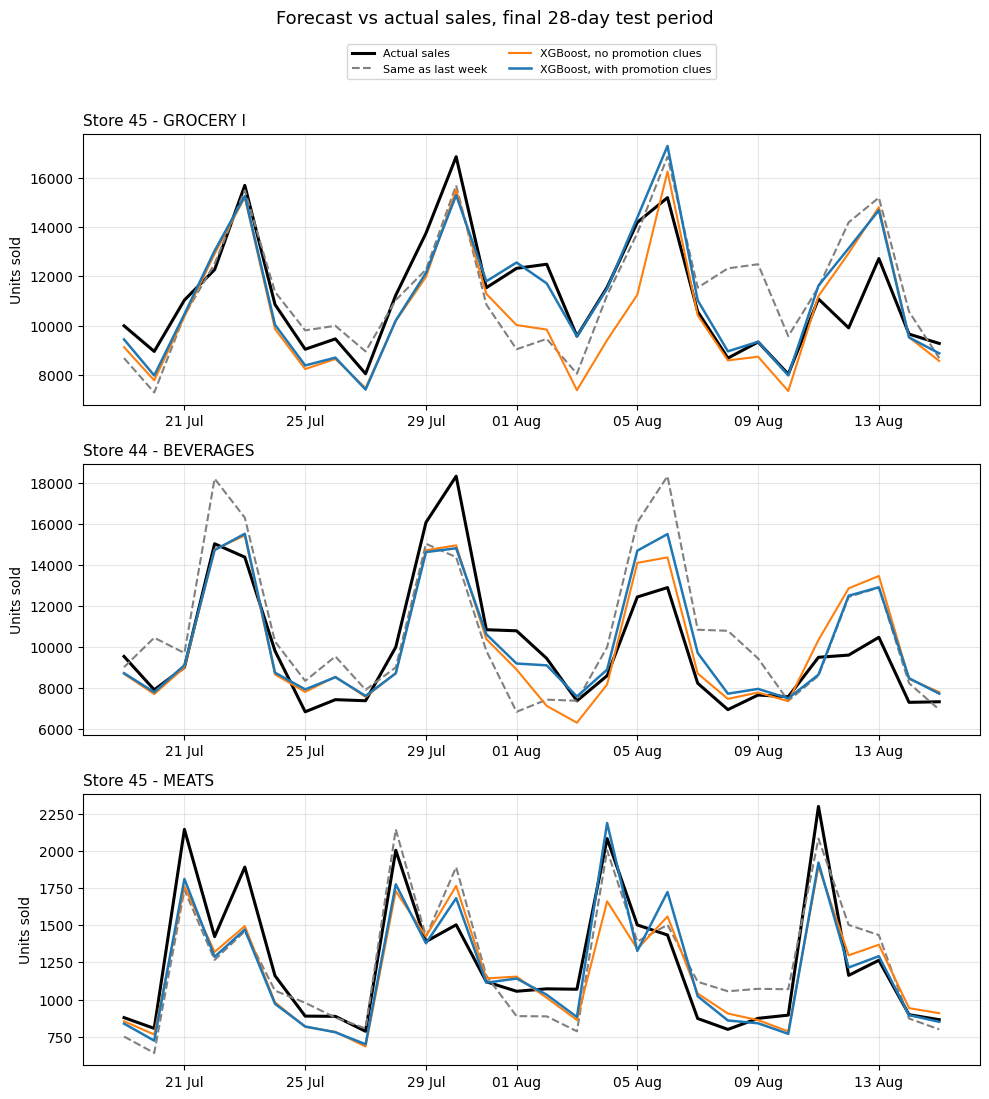

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# pick the best-selling store for 3 product families (Meats shows a less-promoted product)
pairs = []
for fam in ['GROCERY I', 'BEVERAGES', 'MEATS']:
    store = H[H.family == fam].groupby('store_nbr').sales.sum().idxmax()
    pairs.append((store, fam))

fig, axes = plt.subplots(3, 1, figsize=(10, 11))
for ax, (store, fam) in zip(axes, pairs):
    g = H[(H.store_nbr == store) & (H.family == fam)].sort_values('date')
    ax.plot(g.date, g.sales, color='black', lw=2.2, label='Actual sales')
    ax.plot(g.date, g['Same as last week'], '--', color='grey', lw=1.5, label='Same as last week')
    ax.plot(g.date, g['XGBoost (no promo)'], color='tab:orange', lw=1.5, label='XGBoost, no promotion clues')
    ax.plot(g.date, g['XGBoost (promo-aware)'], color='tab:blue', lw=1.8, label='XGBoost, with promotion clues')
    ax.set_title(f'Store {store} - {fam}', fontsize=11, loc='left')
    ax.set_ylabel('Units sold')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.grid(alpha=0.3)
axes[0].legend(loc='upper center', ncol=2, fontsize=8, bbox_to_anchor=(0.5, 1.35))
fig.suptitle('Forecast vs actual sales, final 28-day test period', y=0.995, fontsize=13)
plt.tight_layout()
plt.savefig(f'{BASE}/fig_forecast_vs_actual.png', dpi=200, bbox_inches='tight')
plt.show()

### 28. Visualizing Forecast vs. Actuals
#### Time-Series Analysis over the Holdout Period
This plot compares the actual demand of our top-selling stores against our three core prediction strategies over the final 28-day holdout period, highlighting how well each model captures promotion spikes.

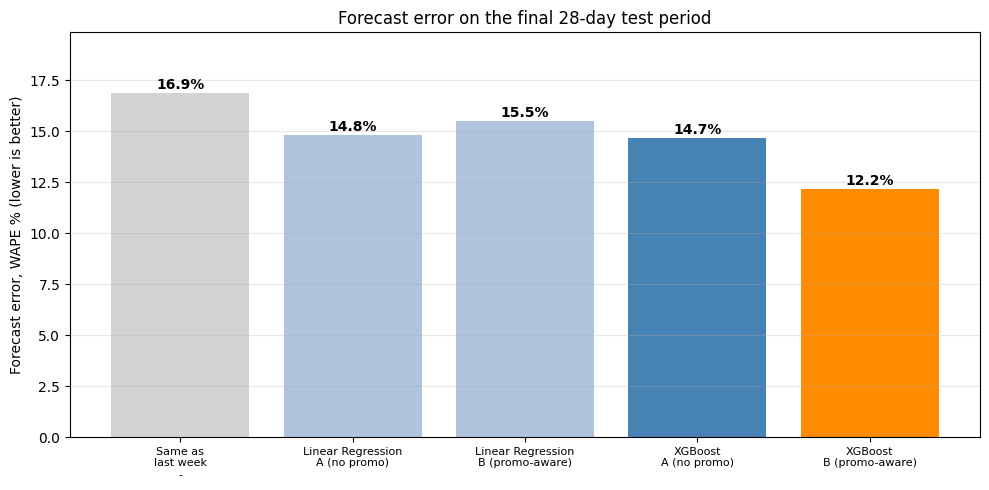

In [ ]:
fin = pd.DataFrame(final)
fin['label'] = fin['model'].str.replace('Same as last week', 'Same as\nlast week') + '\n' + fin['features']

colors = ['lightgrey', 'lightsteelblue', 'lightsteelblue', 'steelblue', 'darkorange']
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(fin['label'], fin['WAPE%'], color=colors)
for b, v in zip(bars, fin['WAPE%']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.2, f'{v:.1f}%', ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('Forecast error, WAPE % (lower is better)')
ax.set_title('Forecast error on the final 28-day test period')
ax.set_ylim(0, fin['WAPE%'].max() + 3)
ax.grid(axis='y', alpha=0.3)
plt.xticks(fontsize=8)
plt.tight_layout()
plt.savefig(f'{BASE}/fig_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

### 29. Test Period Model Comparison
#### Global Evaluation on Holdout Data
We visualize the total forecast error (WAPE %) across all models over the final test split to conclusively identify which modeling configuration delivers the highest baseline accuracy.

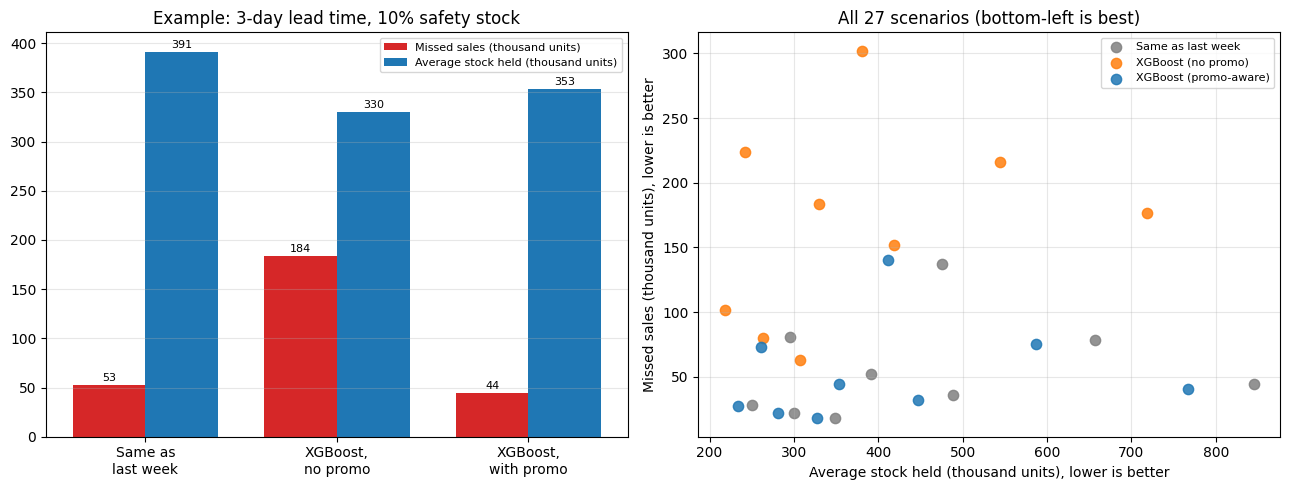

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: one example scenario (3-day lead time, 10% safety stock)
ex = sim[(sim.lead_days == 3) & (sim.safety_stock == '10%')].set_index('forecast').loc[methods]
x = np.arange(len(methods)); w = 0.38
ax = axes[0]
b1 = ax.bar(x - w/2, ex.shortage_units / 1000, w, label='Missed sales (thousand units)', color='tab:red')
b2 = ax.bar(x + w/2, ex.avg_stock_units / 1000, w, label='Average stock held (thousand units)', color='tab:blue')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 4, f'{b.get_height():.0f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(['Same as\nlast week', 'XGBoost,\nno promo', 'XGBoost,\nwith promo'])
ax.set_title('Example: 3-day lead time, 10% safety stock')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)

# Right: all 27 scenarios
ax = axes[1]
cmap = {'Same as last week': 'grey', 'XGBoost (no promo)': 'tab:orange', 'XGBoost (promo-aware)': 'tab:blue'}
for m in methods:
    d = sim[sim.forecast == m]
    ax.scatter(d.avg_stock_units / 1000, d.shortage_units / 1000, s=55, color=cmap[m], label=m, alpha=0.85)
ax.set_xlabel('Average stock held (thousand units), lower is better')
ax.set_ylabel('Missed sales (thousand units), lower is better')
ax.set_title('All 27 scenarios (bottom-left is best)')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{BASE}/fig_inventory_simulation.png', dpi=200, bbox_inches='tight')
plt.show()

### 30. Business Simulation & Decision Curves
#### Balancing Missed Sales and Storage Costs
Using the simulation outputs, we chart a cost-versus-shortage trade-off curve across all 27 operational scenarios to show how a promotion-aware forecasting system saves inventory carrying costs while maintaining high service levels.